In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Phase Space

M = np.array([[0.5, 1],
              [-0.5, 1]])
start = np.array([[1], [1]])

# create a set of M @ start for n = 0, 1, 2, ..., 100
points = [start]
for n in range(20):
    points.append(M @ points[-1])
points = np.array(points).squeeze()

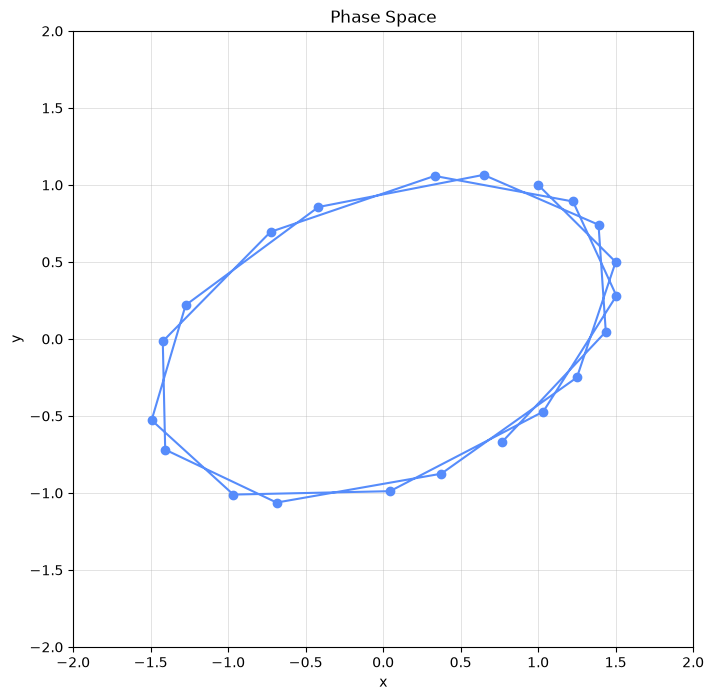

In [3]:
# Plot the points in phase space
plt.figure(figsize=(8, 8))
plt.plot(points[:, 0], points[:, 1], 'o-')
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Phase Space')
plt.grid()

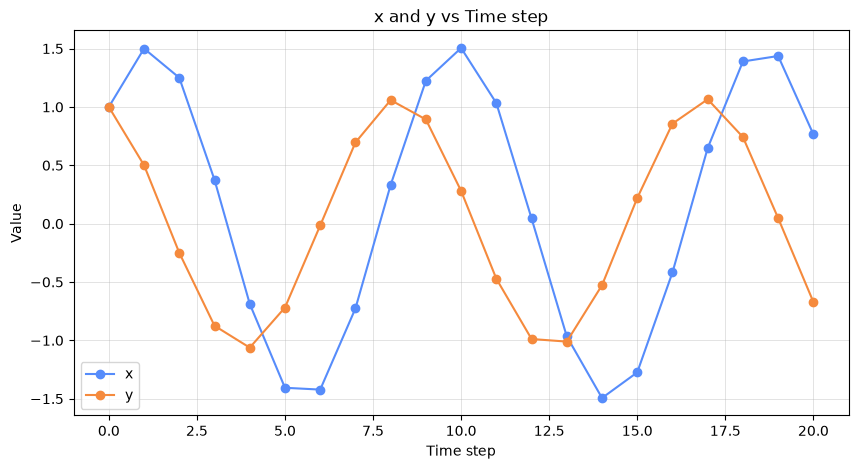

In [4]:
# Plot x and y vs time step in a single graph
plt.figure(figsize=(10, 5))
plt.plot(points[:, 0], 'o-', label='x')
plt.plot(points[:, 1], 'o-', label='y')
plt.xlabel('Time step')
plt.ylabel('Value')
plt.title('x and y vs Time step')
plt.legend()
plt.grid()

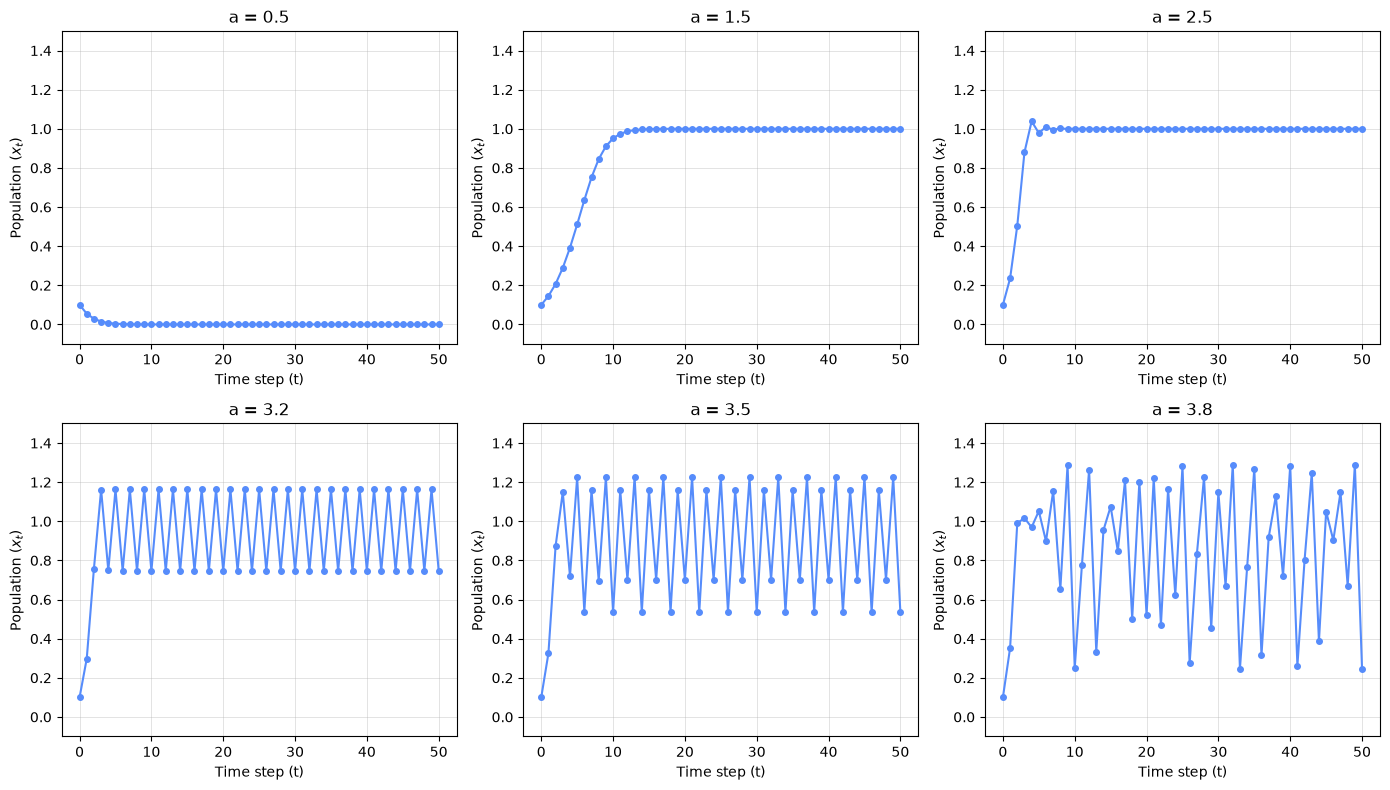

In [5]:
# Exercise 4.9: Population Growth Model Simulation
# x_t = ( - (a - 1) / K * x_{t-1} + a ) * x_{t-1}

def simulate_logistic(a, x0, K=1.0, steps=50):
    x = [x0]
    for _ in range(steps):
        x_next = (- (a - 1) / K * x[-1] + a) * x[-1]
        x.append(x_next)
    return x

# 1. Behavior for different values of parameter 'a'
K = 1.0
x0 = 0.1
steps = 50
a_values = [0.5, 1.5, 2.5, 3.2, 3.5, 3.8]

plt.figure(figsize=(14, 8))
for i, a in enumerate(a_values, 1):
    plt.subplot(2, 3, i)
    traj = simulate_logistic(a=a, x0=x0, K=K, steps=steps)
    plt.plot(traj, 'o-', markersize=4)
    plt.title(f'a = {a}')
    plt.xlabel('Time step (t)')
    plt.ylabel('Population ($x_t$)')
    plt.ylim(-0.1, 1.5)
    plt.grid(True)

plt.tight_layout()
plt.show()

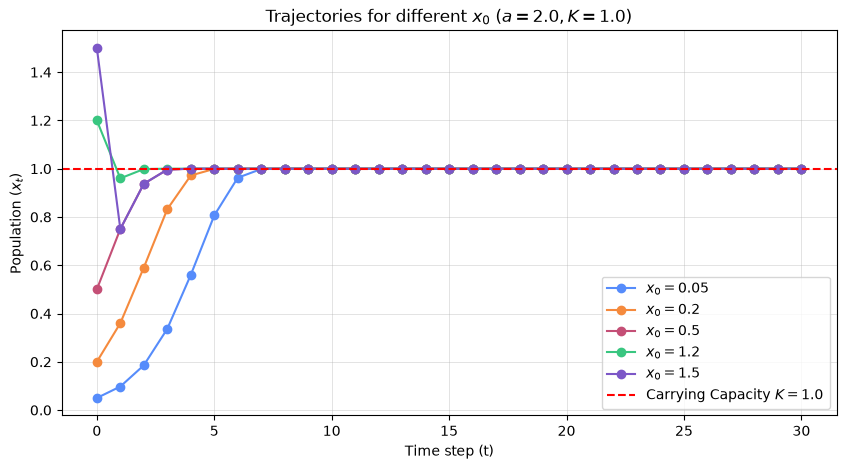

In [6]:
# 2. Behavior for different initial conditions x0
a_fixed = 2.0
x0_values = [0.05, 0.2, 0.5, 1.2, 1.5]

plt.figure(figsize=(10, 5))
for init in x0_values:
    traj = simulate_logistic(a=a_fixed, x0=init, K=K, steps=30)
    plt.plot(traj, 'o-', label=f'$x_0 = {init}$')

plt.axhline(K, color='r', linestyle='--', label=f'Carrying Capacity $K = {K}$')
plt.xlabel('Time step (t)')
plt.ylabel('Population ($x_t$)')
plt.title(f'Trajectories for different $x_0$ ($a = {a_fixed}, K = {K}$)')
plt.legend()
plt.grid(True)
plt.show()